# Single-Node Carbon-Aware Scheduler Visualization

This notebook visualizes power consumption, energy usage, and carbon emissions for single-node training experiments with various parallelism strategies.

In [1]:
# imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "figure.titlesize": 16,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

COLORS = {
    "dp": "#2196F3", "tp": "#4CAF50", "pp": "#FF9800",
    "mixed": "#9C27B0", "schedule": "#E91E63",
}


In [2]:
# settings
from pathlib import Path

def find_repo_root(start=None):
    path = Path(start or os.getcwd()).resolve()
    for candidate in (path, *path.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "power_logs").is_dir():
            return candidate
    raise RuntimeError(f"Could not find repo root from {path}")

BASE = str(find_repo_root())
MODEL_NAME = "llama_1b"
DATA_DIR = os.path.join(BASE, "power_logs", MODEL_NAME)
PLOTS_DIR = os.path.join(BASE, "figures", "experiment_plots", MODEL_NAME)
os.makedirs(PLOTS_DIR, exist_ok=True)
print(f"Repo root: {BASE}")
print(f"Reading power logs from: {DATA_DIR}")
print(f"Saving plots to: {PLOTS_DIR}")

INTERVAL_SECONDS = 0.5
TRAIN_ITERS = 200
GLOBAL_BATCH = 16
SEQ_LEN = 1024

A = [400, 100, 100]   # CI per period (gCO₂/kWh)
CI_FIXED = 400    # baseline constant


Repo root: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism
Reading power logs from: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/power_logs/llama_1b
Saving plots to: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/llama_1b


In [3]:
# helpers
def load_power_csv(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    if "time_step" not in df.columns:
        df.columns = ["timestamp", "total_power_W",
                      "GPU_0_W", "GPU_1_W", "GPU_2_W", "GPU_3_W"]
        df["time_step"] = 0
    return df


def get_ci_schedule_wallclock(n_samples, interval, A, schedule_duration_s):
    ci = np.full(n_samples, A[-1], dtype=float)
    period_s = schedule_duration_s / len(A)
    for i, c in enumerate(A):
        idx_start = max(0, min(int(i * period_s / interval), n_samples))
        idx_end   = max(0, min(int((i + 1) * period_s / interval), n_samples))
        ci[idx_start:idx_end] = c
    return ci


def compute_carbon(power_samples, ci_array, interval=0.5):
    energy_kwh = power_samples * interval / 3_600_000
    grams = energy_kwh * ci_array
    return np.cumsum(grams), grams.sum()


## Setup & Configuration

Load imports, configure plot style, and set analysis parameters.

In [4]:
# ci colors
_CI_CMAP = plt.cm.YlOrRd
_CI_NORM = None

def build_ci_norm(A):
    global _CI_NORM
    ci_min, ci_max = min(A), max(A)
    if ci_max == ci_min:
        _CI_NORM = mcolors.Normalize(vmin=ci_min * 0.9, vmax=ci_max * 1.1)
    else:
        _CI_NORM = mcolors.Normalize(vmin=ci_min, vmax=ci_max)

def ci_to_color(ci_val):
    if _CI_NORM is None:
        raise RuntimeError("Call build_ci_norm(A) first.")
    return _CI_CMAP(_CI_NORM(ci_val))

def ci_label(ci_val, A):
    ci_min, ci_max = min(A), max(A)
    if ci_val == ci_max and ci_val != ci_min:
        return f"{ci_val} g/kWh (high)"
    if ci_val == ci_min and ci_val != ci_max:
        return f"{ci_val} g/kWh (low)"
    return f"{ci_val} g/kWh"

build_ci_norm(A)

def add_ci_colorbar(fig, ax, A, label="CI (gCO₂/kWh)"):
    sm = plt.cm.ScalarMappable(cmap=_CI_CMAP, norm=_CI_NORM)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, orientation="vertical",
                      fraction=0.03, pad=0.02, shrink=0.75)
    cb.set_label(label, fontsize=12)
    cb.set_ticks(sorted(set(A)))
    cb.set_ticklabels([ci_label(c, A) for c in sorted(set(A))])
    return cb


def _classify(cfg):
    if cfg["is_schedule"]:
        return "schedule"
    dims_gt1 = sum(1 for d in (cfg["tp"], cfg["pp"], cfg["dp"]) if d > 1)
    if dims_gt1 >= 2: return "mixed"
    if cfg["tp"] > 1: return "tp"
    if cfg["pp"] > 1: return "pp"
    return "dp"


def _label(cfg):
    if cfg["is_schedule"]:
        return "Hybrid\nSchedule"
    parts = []
    if cfg["tp"] > 1: parts.append(f"TP={cfg['tp']}")
    if cfg["pp"] > 1: parts.append(f"PP={cfg['pp']}")
    if cfg["dp"] > 1: parts.append(f"DP={cfg['dp']}")
    return ",".join(parts) if parts else "DP=1"


def annotate_ci_periods(ax, A, schedule_duration_s, y_label_frac=0.04):
    period_s = schedule_duration_s / len(A)
    ylo, yhi = ax.get_ylim()
    y_text = ylo + (yhi - ylo) * y_label_frac
    for i, c in enumerate(A):
        x0, x1 = i * period_s, (i + 1) * period_s
        ax.axvspan(x0, x1, alpha=0.18, color=ci_to_color(c), zorder=0)
        ax.text((x0 + x1) / 2, y_text, ci_label(c, A),
                ha="center", va="bottom", fontsize=12,
                fontweight="bold", color=ci_to_color(c), alpha=0.85)
    xlim = ax.get_xlim()
    if xlim[1] > schedule_duration_s:
        ax.axvspan(schedule_duration_s, xlim[1], alpha=0.10,
                   color=ci_to_color(A[-1]), zorder=0)


In [5]:
# load csvs compute
all_possible_configs = {
    "tp1_pp1_dp4": {"tp": 1, "pp": 1, "dp": 4, "file": "elastic_tp1_pp1_dp4_power.csv", "is_schedule": False},
    "tp4_pp1_dp1": {"tp": 4, "pp": 1, "dp": 1, "file": "elastic_tp4_pp1_dp1_power.csv", "is_schedule": False},
    "tp1_pp4_dp1": {"tp": 1, "pp": 4, "dp": 1, "file": "elastic_tp1_pp4_dp1_power.csv", "is_schedule": False},
    "tp2_pp2_dp1": {"tp": 2, "pp": 2, "dp": 1, "file": "elastic_tp2_pp2_dp1_power.csv", "is_schedule": False},
    "tp2_pp1_dp2": {"tp": 2, "pp": 1, "dp": 2, "file": "elastic_tp2_pp1_dp2_power.csv", "is_schedule": False},
    "tp1_pp2_dp2": {"tp": 1, "pp": 2, "dp": 2, "file": "elastic_tp1_pp2_dp2_power.csv", "is_schedule": False},
}

schedule_configs_def = {
    "hybrid_schedule": {
        "tp": None, "pp": None, "dp": None,
        "file": "elastic_example_schedule_power.csv",
        "is_schedule": True,
    },
}

def load_configs():
    loaded = {}
    skipped = []
    for name, cfg_template in {**all_possible_configs, **schedule_configs_def}.items():
        cfg = cfg_template.copy()
        path = os.path.join(DATA_DIR, cfg["file"])
        if not os.path.exists(path):
            skipped.append(name)
            continue
        df = load_power_csv(path)
        if len(df) < 2:
            skipped.append(name)
            continue
        warmup = int(len(df) * 0.2)
        steady = df.iloc[warmup:]
        cfg["avg_power"] = df["total_power_W"].mean()
        cfg["steady_avg_power"] = steady["total_power_W"].mean()
        cfg["peak_power"] = df["total_power_W"].max()
        cfg["df"] = df
        loaded[name] = cfg
        tag = " [SCHED]" if cfg["is_schedule"] else ""
        print(f"{name}{tag}: avg={cfg['avg_power']:.1f}W  "
              f"steady={cfg['steady_avg_power']:.1f}W  samples={len(df)}")
    return loaded, skipped

configs, skipped = load_configs()

if skipped:
    print(f"\nSkipped: {', '.join(skipped)}")

static_configs = {k: v for k, v in configs.items() if not v["is_schedule"]}
sched_configs  = {k: v for k, v in configs.items() if v["is_schedule"]}
n_configs = len(configs)
all_configs = [(_label(cfg), _classify(cfg), cfg) for _, cfg in configs.items()]


tp1_pp1_dp4: avg=772.4W  steady=872.0W  samples=847
tp4_pp1_dp1: avg=540.1W  steady=562.1W  samples=1920
tp1_pp4_dp1: avg=672.8W  steady=734.3W  samples=1044
tp2_pp2_dp1: avg=579.3W  steady=615.4W  samples=1456
tp2_pp1_dp2: avg=665.4W  steady=725.6W  samples=1118
tp1_pp2_dp2: avg=757.8W  steady=853.0W  samples=868
hybrid_schedule [SCHED]: avg=584.0W  steady=628.9W  samples=1495


## Single-Model Analysis

Load power logs for various parallelism configurations (DP, TP, PP, mixed) and compute key metrics.

In [6]:
# 4b derive ci
if not globals().get("configs") and "load_configs" in globals():
    print("configs is empty; reloading power CSVs from DATA_DIR...")
    configs, skipped = load_configs()
    if skipped:
        print(f"Skipped: {', '.join(skipped)}")
    static_configs = {k: v for k, v in configs.items() if not v["is_schedule"]}
    sched_configs  = {k: v for k, v in configs.items() if v["is_schedule"]}
    n_configs = len(configs)
    all_configs = [(_label(cfg), _classify(cfg), cfg) for _, cfg in configs.items()]

if not globals().get("configs"):
    raise RuntimeError(
        "No configs loaded — cannot derive schedule duration. "
        f"Checked DATA_DIR={DATA_DIR!r}; verify MODEL_NAME and rerun the load csvs cell."
    )

CI_SCHEDULE_DURATION_S = max(len(cfg["df"]) for cfg in configs.values()) * INTERVAL_SECONDS
slowest = max(configs.items(), key=lambda kv: len(kv[1]["df"]))[0]
print(f"\nCI schedule duration (derived): {CI_SCHEDULE_DURATION_S:.1f}s "
      f"(slowest = {slowest})")
print(f"Each of the {len(A)} periods covers "
      f"{CI_SCHEDULE_DURATION_S / len(A):.1f}s of wall-clock time.")



CI schedule duration (derived): 960.0s (slowest = tp4_pp1_dp1)
Each of the 3 periods covers 320.0s of wall-clock time.


In [7]:
# metrics
total_tokens = TRAIN_ITERS * GLOBAL_BATCH * SEQ_LEN

print(f"\n{'Label':20s} | {'Time':>6s} | {'Power':>7s} | "
      f"{'Energy':>7s} | {'C_fix':>7s} | {'C_var':>7s} | {'Tput':>9s}")
print("-" * 82)

for label, _, cfg in all_configs:
    power = cfg["df"]["total_power_W"].to_numpy()
    n = len(power)
    total_time_s = n * INTERVAL_SECONDS
    cfg["train_time_s"] = total_time_s
    cfg["total_time_s"] = total_time_s
    cfg["avg_power_w"] = power.mean()
    cfg["total_energy_wh"] = power.sum() * INTERVAL_SECONDS / 3600
    cfg["tokens_per_sec"] = total_tokens / total_time_s

    _, cfg["carbon_fixed_g"] = compute_carbon(power, np.full(n, CI_FIXED))
    ci_var = get_ci_schedule_wallclock(n, INTERVAL_SECONDS, A, CI_SCHEDULE_DURATION_S)
    _, cfg["carbon_varying_g"] = compute_carbon(power, ci_var)

    tag = " ★" if cfg["is_schedule"] else ""
    print(f"{label.replace(chr(10),' '):20s} | {total_time_s:5.1f}s | "
          f"{cfg['avg_power_w']:6.1f}W | {cfg['total_energy_wh']:6.2f}Wh | "
          f"{cfg['carbon_fixed_g']:5.1f}g | {cfg['carbon_varying_g']:5.1f}g | "
          f"{cfg['tokens_per_sec']:7.1f} t/s{tag}")



Label                |   Time |   Power |  Energy |   C_fix |   C_var |      Tput
----------------------------------------------------------------------------------
DP=4                 | 423.5s |  772.4W |  90.86Wh |  36.3g |  29.0g |  7737.4 t/s
TP=4                 | 960.0s |  540.1W | 144.02Wh |  57.6g |  27.7g |  3413.3 t/s
PP=4                 | 522.0s |  672.8W |  97.55Wh |  39.0g |  26.7g |  6277.4 t/s
TP=2,PP=2            | 728.0s |  579.3W | 117.14Wh |  46.9g |  26.0g |  4501.1 t/s
TP=2,DP=2            | 559.0s |  665.4W | 103.32Wh |  41.3g |  26.9g |  5861.9 t/s
PP=2,DP=2            | 434.0s |  757.8W |  91.36Wh |  36.5g |  28.6g |  7550.2 t/s
Hybrid Schedule      | 747.5s |  584.0W | 121.26Wh |  48.5g |  25.1g |  4383.7 t/s ★


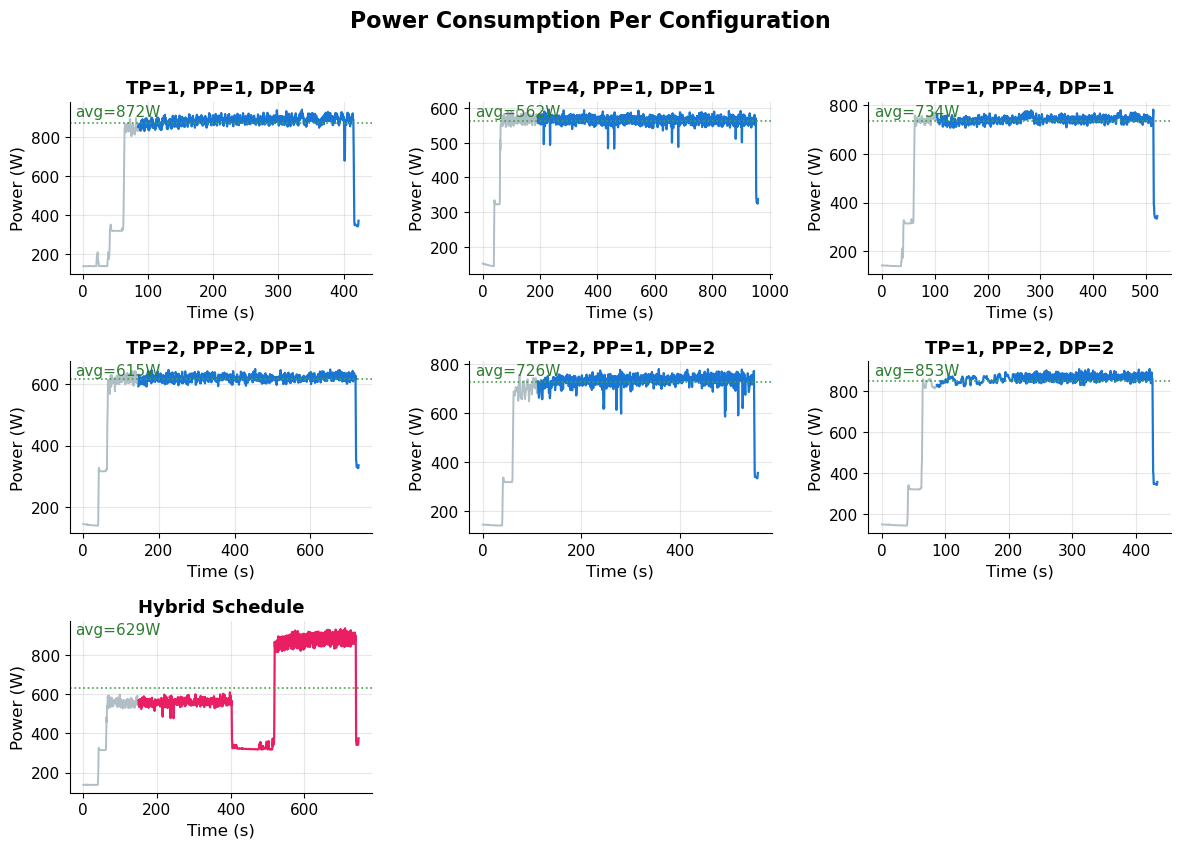

In [8]:
# power traces config
if n_configs > 0:
    ncols = min(3, n_configs)
    nrows = (n_configs + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.8 * nrows))
    axes = np.atleast_1d(axes).flatten()

    for ax, (name, cfg) in zip(axes, configs.items()):
        df = cfg["df"]
        warmup_idx = int(len(df) * 0.2)
        x = np.arange(len(df)) * INTERVAL_SECONDS
        y = df["total_power_W"].to_numpy()

        ax.plot(x[:warmup_idx], y[:warmup_idx], color="#B0BEC5", linewidth=1.4)
        ax.plot(x[warmup_idx:], y[warmup_idx:],
                color=COLORS["schedule"] if cfg["is_schedule"] else "#1976D2",
                linewidth=1.6)
        ax.axhline(cfg["steady_avg_power"], color="#43A047", linestyle=":", linewidth=1.2)

        if cfg["is_schedule"]:
            title = "Hybrid Schedule"
            steps = df["time_step"].to_numpy()
            for j in range(1, len(steps)):
                if steps[j] < steps[j-1] and steps[j-1] > 0:
                    ax.axvline(x[j], color="#FF9800", linestyle="-.", linewidth=0.8, alpha=0.7)
        else:
            title = f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}"

        ax.set_title(title, fontsize=13, fontweight="bold")
        ax.set_xlabel("Time (s)", fontsize=12)
        ax.set_ylabel("Power (W)", fontsize=12)
        ax.tick_params(labelsize=11)
        ax.text(0.02, 0.92, f"avg={cfg['steady_avg_power']:.0f}W",
                transform=ax.transAxes, fontsize=11, color="#2E7D32")

    for ax in axes[n_configs:]:
        ax.set_visible(False)

    fig.suptitle("Power Consumption Per Configuration", fontsize=16, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph0_power_trends.png"), dpi=300, bbox_inches="tight")
    plt.show()


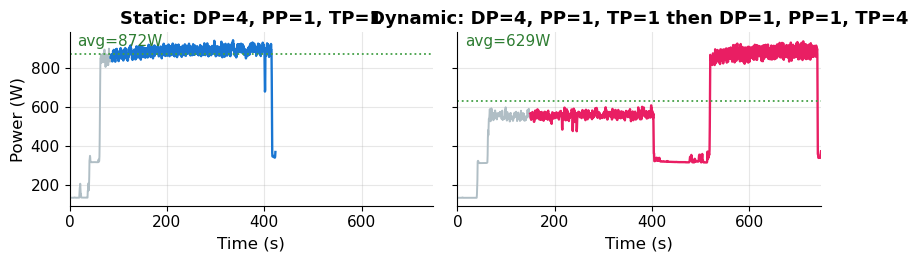

In [9]:
# power trace figure: static DP=4 vs dynamic strategy
static_key = None
dynamic_key = None

for name, cfg in configs.items():
    if (
        not cfg.get("is_schedule", False)
        and cfg.get("dp") == 4
        and cfg.get("pp") == 1
        and cfg.get("tp") == 1
    ):
        static_key = name

    if cfg.get("is_schedule", False):
        dynamic_key = name

if static_key is None:
    raise ValueError("Could not find static strategy with DP=4, PP=1, TP=1")

if dynamic_key is None:
    raise ValueError("Could not find dynamic strategy where cfg['is_schedule'] is True")

schedule_color = COLORS.get("schedule", "#D81B60") if "COLORS" in globals() else "#D81B60"

selected = [
    ("Static: DP=4, PP=1, TP=1", configs[static_key], "#1976D2"),
    ("Dynamic: DP=4, PP=1, TP=1 then DP=1, PP=1, TP=4", configs[dynamic_key], schedule_color),
]

# Precompute traces so both panels use identical x/y limits.
traces = []
for title, cfg, color in selected:
    df = cfg["df"]
    warmup_idx = int(len(df) * 0.2)

    x = np.arange(len(df)) * INTERVAL_SECONDS
    y = df["total_power_W"].to_numpy()

    traces.append({
        "title": title,
        "cfg": cfg,
        "df": df,
        "warmup_idx": warmup_idx,
        "x": x,
        "y": y,
        "color": color,
    })

x_max = max(trace["x"][-1] for trace in traces)
y_min = min(np.nanmin(trace["y"]) for trace in traces)
y_max = max(np.nanmax(trace["y"]) for trace in traces)
y_pad = 0.05 * (y_max - y_min) if y_max > y_min else 10

fig, axes = plt.subplots(
    1,
    2,
    figsize=(8.5, 2.8),
    sharex=True,
    sharey=True,
)

for ax, trace in zip(axes, traces):
    cfg = trace["cfg"]
    df = trace["df"]
    x = trace["x"]
    y = trace["y"]
    warmup_idx = trace["warmup_idx"]

    # Warmup region
    ax.plot(
        x[:warmup_idx],
        y[:warmup_idx],
        color="#B0BEC5",
        linewidth=1.4,
        label="Warmup",
    )

    # Steady region
    ax.plot(
        x[warmup_idx:],
        y[warmup_idx:],
        color=trace["color"],
        linewidth=1.7,
        label="Measured power",
    )

    # Steady-state average
    ax.axhline(
        cfg["steady_avg_power"],
        color="#43A047",
        linestyle=":",
        linewidth=1.3,
        label="Steady avg.",
    )

    # Mark dynamic strategy switches.
    if cfg.get("is_schedule", False):
        steps = df["time_step"].to_numpy()

        for j in range(1, len(steps)):
            if steps[j] < steps[j - 1] and steps[j - 1] > 0:
                ax.axvline(
                    x[j],
                    color="#FF9800",
                    linestyle="-.",
                    linewidth=0.9,
                    alpha=0.75,
                )

    ax.set_title(trace["title"], fontsize=13, fontweight="bold")
    ax.set_xlabel("Time (s)", fontsize=12)
    ax.tick_params(labelsize=11)

    ax.text(
        0.02,
        0.92,
        f"avg={cfg['steady_avg_power']:.0f}W",
        transform=ax.transAxes,
        fontsize=11,
        color="#2E7D32",
    )

    # Force identical axes across both plots.
    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)

axes[0].set_ylabel("Power (W)", fontsize=12)

fig.align_xlabels(axes)
fig.align_ylabels(axes)

plt.tight_layout()
plt.savefig(
    os.path.join(PLOTS_DIR, "graph_static_vs_dynamic_power.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Power Traces

Visualize power consumption over time for each configuration during training.


CI SCHEDULE:  A = [400, 100, 100] gCO₂/kWh over 960s
  Period 1: 0–320s → 400 g/kWh (high)
  Period 2: 320–640s → 100 g/kWh (low)
  Period 3: 640–960s → 100 g/kWh (low)
Fixed baseline: 400 gCO₂/kWh


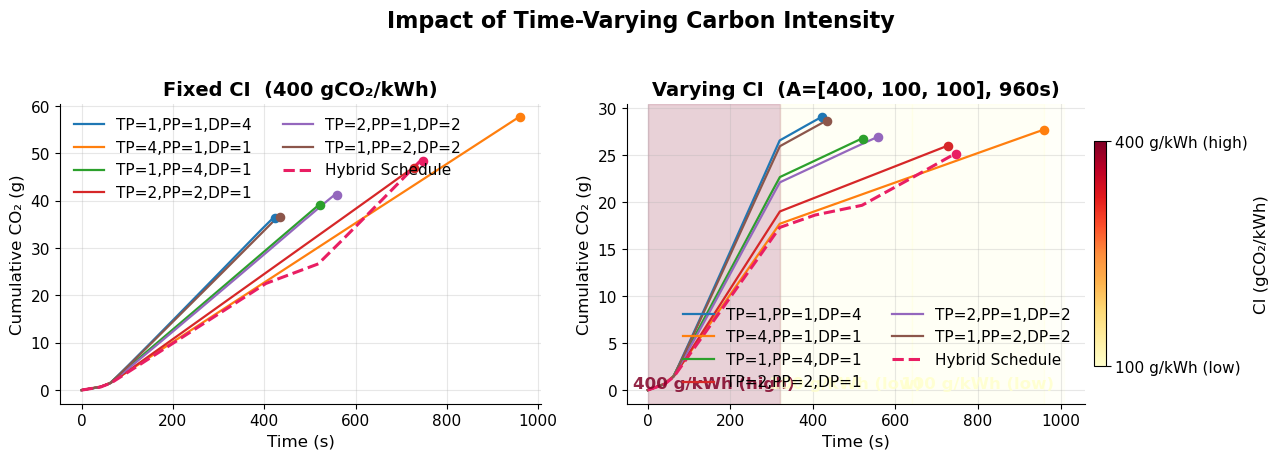

In [10]:
# fixed vs varying
print("\n" + "=" * 72)
print(f"CI SCHEDULE:  A = {A} gCO₂/kWh over {CI_SCHEDULE_DURATION_S:.0f}s")
period_s = CI_SCHEDULE_DURATION_S / len(A)
for i, c in enumerate(A):
    print(f"  Period {i+1}: {i*period_s:.0f}–{(i+1)*period_s:.0f}s → {ci_label(c, A)}")
print(f"Fixed baseline: {CI_FIXED} gCO₂/kWh")
print("=" * 72)

if n_configs > 0:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    for ax, use_varying in zip(axes, [False, True]):
        for name, cfg in configs.items():
            power = cfg["df"]["total_power_W"].to_numpy()
            n = len(power)
            ci = (get_ci_schedule_wallclock(n, INTERVAL_SECONDS, A, CI_SCHEDULE_DURATION_S)
                  if use_varying else np.full(n, CI_FIXED))
            cum, _ = compute_carbon(power, ci)
            x = np.arange(n) * INTERVAL_SECONDS

            style = {"linewidth": 2.2, "linestyle": "--"} if cfg["is_schedule"] else {"linewidth": 1.6}
            lbl = "Hybrid Schedule" if cfg["is_schedule"] else \
                  f"TP={cfg['tp']},PP={cfg['pp']},DP={cfg['dp']}"
            color = COLORS["schedule"] if cfg["is_schedule"] else None
            ax.plot(x, cum, label=lbl, color=color, **style)
            ax.scatter(x[-1], cum[-1], s=35, zorder=3, color=color)

        if use_varying:
            annotate_ci_periods(ax, A, CI_SCHEDULE_DURATION_S)
            ax.set_title(f"Varying CI  (A={A}, {CI_SCHEDULE_DURATION_S:.0f}s)",
                         fontsize=14, fontweight="bold")
            add_ci_colorbar(fig, ax, A)
        else:
            ax.set_title(f"Fixed CI  ({CI_FIXED} gCO₂/kWh)", fontsize=14, fontweight="bold")

        ax.set_xlabel("Time (s)", fontsize=12)
        ax.set_ylabel("Cumulative CO₂ (g)", fontsize=12)
        ax.legend(fontsize=11, ncol=2, frameon=False)

    plt.suptitle("Impact of Time-Varying Carbon Intensity",
                 fontsize=16, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_carbon_varying_ci.png"),
                dpi=300, bbox_inches="tight")
    plt.show()


### Carbon Emissions: Fixed vs Time-Varying CI

Compare cumulative carbon emissions under fixed CI (baseline) vs time-varying CI schedule.

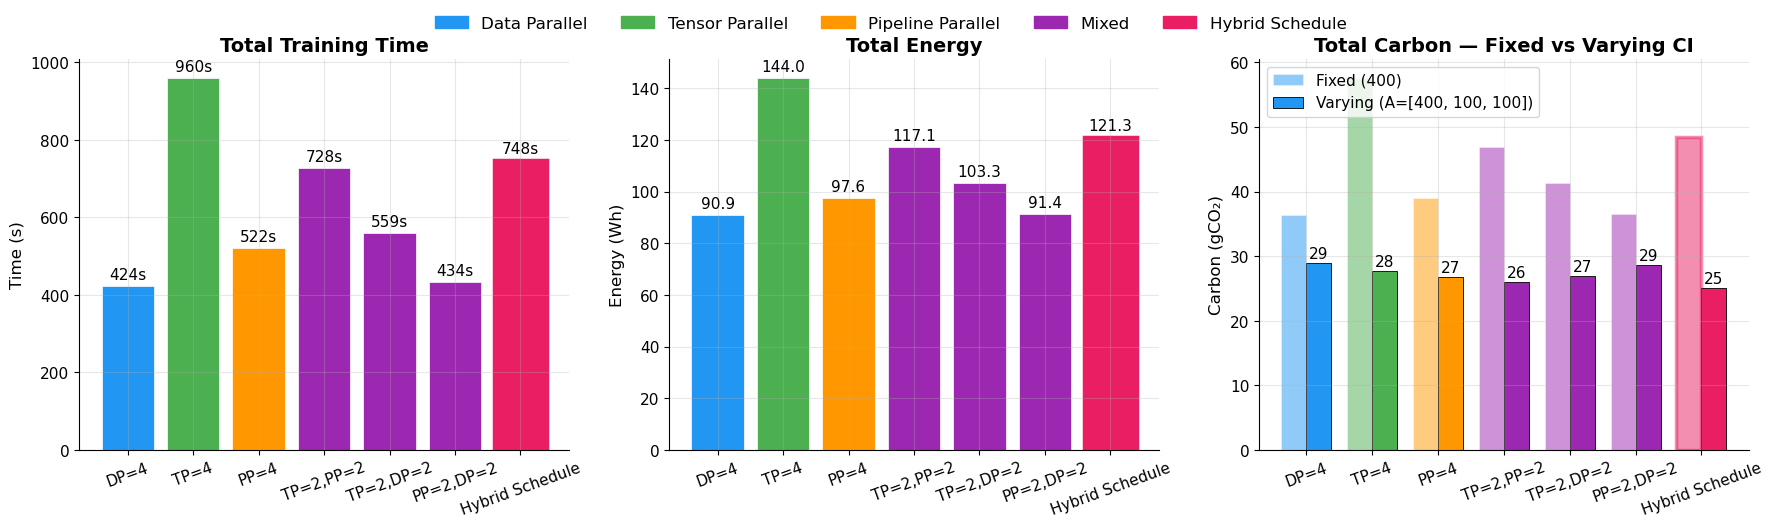

In [11]:
# compact bar chart
patches = [
    mpatches.Patch(color=COLORS["dp"],       label="Data Parallel"),
    mpatches.Patch(color=COLORS["tp"],       label="Tensor Parallel"),
    mpatches.Patch(color=COLORS["pp"],       label="Pipeline Parallel"),
    mpatches.Patch(color=COLORS["mixed"],    label="Mixed"),
    mpatches.Patch(color=COLORS["schedule"], label="Hybrid Schedule"),
]

if all_configs:
    labels_bar = [c[0].replace("\n", " ") for c in all_configs]
    colors_bar = [COLORS[c[1]] for c in all_configs]
    time_vals      = [c[2]["train_time_s"]     for c in all_configs]
    energy_vals    = [c[2]["total_energy_wh"]  for c in all_configs]
    carbon_fixed   = [c[2]["carbon_fixed_g"]   for c in all_configs]
    carbon_varying = [c[2]["carbon_varying_g"] for c in all_configs]
    is_sched       = [c[2]["is_schedule"]      for c in all_configs]

    edge_colors = ["#E91E63" if s else "white" for s in is_sched]
    edge_widths = [2.5 if s else 0.5 for s in is_sched]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

    # panel 1: total time
    ax = axes[0]
    ax.bar(labels_bar, time_vals, color=colors_bar,
           edgecolor=edge_colors, linewidth=edge_widths)
    for i, v in enumerate(time_vals):
        ax.text(i, v + max(time_vals) * 0.01, f"{v:.0f}s",
                ha="center", va="bottom", fontsize=11)
    ax.set_ylabel("Time (s)", fontsize=12)
    ax.set_title("Total Training Time", fontsize=14, fontweight="bold")
    ax.tick_params(axis="x", labelsize=11, rotation=20)

    # panel 2: total energy
    ax = axes[1]
    ax.bar(labels_bar, energy_vals, color=colors_bar,
           edgecolor=edge_colors, linewidth=edge_widths)
    for i, v in enumerate(energy_vals):
        ax.text(i, v + max(energy_vals) * 0.01, f"{v:.1f}",
                ha="center", va="bottom", fontsize=11)
    ax.set_ylabel("Energy (Wh)", fontsize=12)
    ax.set_title("Total Energy", fontsize=14, fontweight="bold")
    ax.tick_params(axis="x", labelsize=11, rotation=20)

    # panel 3: carbon fixed vs varying
    ax = axes[2]
    x = np.arange(len(labels_bar))
    width = 0.38
    ax.bar(x - width/2, carbon_fixed, width, color=colors_bar,
           alpha=0.5, edgecolor=edge_colors, linewidth=edge_widths,
           label=f"Fixed ({CI_FIXED})")
    ax.bar(x + width/2, carbon_varying, width, color=colors_bar,
           edgecolor="black", linewidth=0.6,
           label=f"Varying (A={A})")
    for xi, vv in zip(x, carbon_varying):
        ax.text(xi + width/2, vv + max(carbon_varying) * 0.01,
                f"{vv:.0f}", ha="center", va="bottom", fontsize=11)
    ax.set_ylabel("Carbon (gCO₂)", fontsize=12)
    ax.set_title("Total Carbon — Fixed vs Varying CI", fontsize=14, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels_bar, fontsize=11, rotation=20)
    ax.legend(fontsize=11, loc="upper left")

    fig.legend(handles=patches, fontsize=12, ncol=5,
               loc="upper center", bbox_to_anchor=(0.5, 1.03), frameon=False)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_metrics_overview.png"),
                dpi=300, bbox_inches="tight")
    plt.show()


### Metrics Overview

Summary bar charts: training time, energy, and carbon emissions comparison.

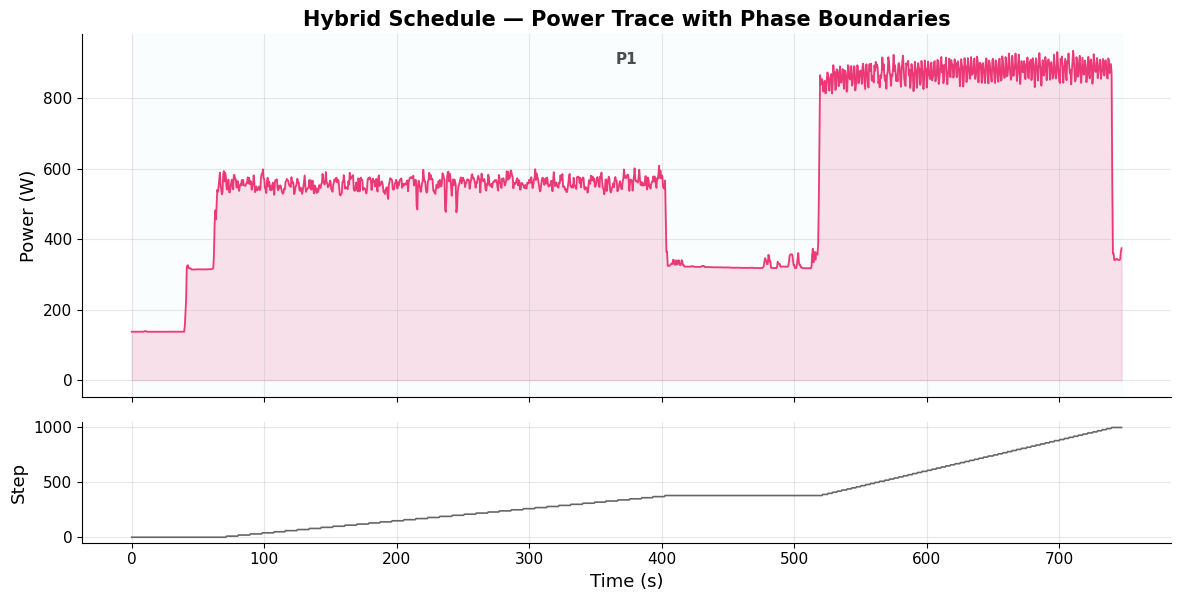

In [12]:
# schedule detail power
for name, cfg in sched_configs.items():
    df = cfg["df"]
    x = np.arange(len(df)) * INTERVAL_SECONDS
    y = df["total_power_W"].to_numpy()
    steps = df["time_step"].to_numpy()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True,
                                    gridspec_kw={"height_ratios": [3, 1]})

    ax1.plot(x, y, color=COLORS["schedule"], linewidth=1.3, alpha=0.85)
    ax1.fill_between(x, y, alpha=0.15, color=COLORS["schedule"])
    ax1.set_ylabel("Power (W)", fontsize=13)
    ax1.set_title("Hybrid Schedule — Power Trace with Phase Boundaries",
                  fontsize=15, fontweight="bold")

    phase_colors = ["#E3F2FD", "#E8F5E9", "#FFF3E0", "#F3E5F5",
                    "#FCE4EC", "#E0F7FA", "#FFF9C4"]
    boundaries = [0]
    for j in range(1, len(steps)):
        if steps[j] < steps[j-1] and steps[j-1] > 0:
            boundaries.append(j)
    boundaries.append(len(df))

    for p_idx in range(len(boundaries) - 1):
        s_idx = boundaries[p_idx]
        e_idx = boundaries[p_idx + 1]
        if s_idx < len(x) and e_idx <= len(x):
            ax1.axvspan(x[s_idx], x[min(e_idx - 1, len(x) - 1)],
                        alpha=0.15, color=phase_colors[p_idx % len(phase_colors)])
            mid_x = (x[s_idx] + x[min(e_idx - 1, len(x) - 1)]) / 2
            ax1.text(mid_x, ax1.get_ylim()[1] * 0.95, f"P{p_idx + 1}",
                     ha="center", va="top", fontsize=11, fontweight="bold", alpha=0.7)

    ax2.plot(x, steps, color="#666", linewidth=1.2)
    ax1.tick_params(labelsize=11)
    ax2.set_xlabel("Time (s)", fontsize=13)
    ax2.set_ylabel("Step", fontsize=13)
    ax2.tick_params(labelsize=11)

    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_schedule_detailed.png"),
                dpi=300, bbox_inches="tight")
    plt.show()


### Schedule Analysis

Detailed power trace with phase boundaries and step markers for hybrid schedule.

In [13]:
# summary
if all_configs:
    summary_rows = []
    for label, _, cfg in all_configs:
        summary_rows.append({
            "Config":           label.replace("\n", " "),
            "Type":             "Schedule" if cfg["is_schedule"] else "Static",
            "Time(s)":          round(cfg["train_time_s"], 1),
            "Avg Power(W)":     round(cfg["avg_power_w"], 1),
            "Energy(Wh)":       round(cfg["total_energy_wh"], 2),
            f"C_Fixed@{CI_FIXED}(g)": round(cfg["carbon_fixed_g"], 2),
            "C_Vary(g)":        round(cfg["carbon_varying_g"], 2),
            "Tput(tok/s)":      round(cfg["tokens_per_sec"], 1),
        })

    summary_df = pd.DataFrame(summary_rows)
    print("\n" + "=" * 95)
    print("SUMMARY TABLE")
    print("=" * 95)
    print(summary_df.to_string(index=False))
    summary_df.to_csv(os.path.join(PLOTS_DIR, "summary_table.csv"), index=False)
    print(f"\nSaved: {os.path.join(PLOTS_DIR, 'summary_table.csv')}")


SUMMARY TABLE
         Config     Type  Time(s)  Avg Power(W)  Energy(Wh)  C_Fixed@400(g)  C_Vary(g)  Tput(tok/s)
           DP=4   Static    423.5         772.4       90.86           36.34      29.00       7737.4
           TP=4   Static    960.0         540.1      144.02           57.61      27.67       3413.3
           PP=4   Static    522.0         672.8       97.55           39.02      26.75       6277.4
      TP=2,PP=2   Static    728.0         579.3      117.14           46.86      25.96       4501.1
      TP=2,DP=2   Static    559.0         665.4      103.32           41.33      26.90       5861.9
      PP=2,DP=2   Static    434.0         757.8       91.36           36.54      28.59       7550.2
Hybrid Schedule Schedule    747.5         584.0      121.26           48.50      25.10       4383.7

Saved: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/llama_1b/summary_table.csv


In [14]:
# model savings
MODEL_PARAMS_M = {
    "gpt2":         124,
    "gpt2_medium":  355,
    "gpt2_large":   774,
    "llama_1b":    1100,
    "llama_2b":    2000,
    "llama_3b":    3000,
}

FAMILIES = {
    "gpt2":  {
        "models": ["gpt2", "gpt2_medium", "gpt2_large"],
        "A":      [600, 300, 300],
        "title":  "GPT-2 family",
    },
    "llama": {
        "models": ["llama_1b", "llama_2b", "llama_3b"],
        "A":      [400, 100, 100],
        "title":  "Llama family",
    },
}

STATIC_FILES = [
    "elastic_tp1_pp1_dp4_power.csv",
    "elastic_tp4_pp1_dp1_power.csv",
    "elastic_tp1_pp4_dp1_power.csv",
    "elastic_tp2_pp2_dp1_power.csv",
    "elastic_tp2_pp1_dp2_power.csv",
    "elastic_tp1_pp2_dp2_power.csv",
]
SCHEDULE_FILE = "elastic_example_schedule_power.csv"

CROSS_PLOTS_DIR = os.path.join(BASE, "figures", "experiment_plots", "cross_model")
os.makedirs(CROSS_PLOTS_DIR, exist_ok=True)


def _load_runs(ddir, files):
    out = {}
    for f in files:
        p = os.path.join(ddir, f)
        if not os.path.exists(p):
            continue
        df = load_power_csv(p)
        if len(df) >= 2:
            out[f] = df
    return out


def _carbon_varying(df, A_family, schedule_duration_s):
    power = df["total_power_W"].to_numpy()
    ci = get_ci_schedule_wallclock(len(power), INTERVAL_SECONDS,
                                   A_family, schedule_duration_s)
    _, total = compute_carbon(power, ci, INTERVAL_SECONDS)
    return total


def _collect_family_rows(models, A_family):
    rows = []
    for m in sorted(models, key=lambda x: MODEL_PARAMS_M.get(x, 0)):
        ddir = os.path.join(BASE, "power_logs", m)
        if not os.path.isdir(ddir):
            print(f"[skip] {m}: no directory")
            continue

        static_runs = _load_runs(ddir, STATIC_FILES)
        sched_runs  = _load_runs(ddir, [SCHEDULE_FILE])
        if not static_runs or not sched_runs:
            print(f"[skip] {m}: missing runs")
            continue

        all_runs = {**static_runs, **sched_runs}
        sched_dur_s = max(len(df) for df in all_runs.values()) * INTERVAL_SECONDS

        static_carbons = [_carbon_varying(df, A_family, sched_dur_s)
                          for df in static_runs.values()]
        sched_carbon   = _carbon_varying(next(iter(sched_runs.values())),
                                         A_family, sched_dur_s)

        best_fixed = min(static_carbons)
        saving_pct = (best_fixed - sched_carbon) / best_fixed * 100

        rows.append({
            "model":        m,
            "params_M":     MODEL_PARAMS_M.get(m, 0),
            "sched_dur_s":  sched_dur_s,
            "best_fixed_g": best_fixed,
            "schedule_g":   sched_carbon,
            "saving_pct":   saving_pct,
        })
        print(f"{m:15s} | window={sched_dur_s:6.0f}s | "
              f"best fixed={best_fixed:7.1f}g | schedule={sched_carbon:7.1f}g | "
              f"saved={saving_pct:+5.1f}%")
    return rows


def _plot_family(rows, A_family, title, outfile):
    if len(rows) < 2:
        print(f"[skip plot] {title}: need ≥2 models, got {len(rows)}")
        return
    params  = [r["params_M"]    for r in rows]
    savings = [r["saving_pct"]  for r in rows]
    names   = [r["model"]       for r in rows]
    windows = [r["sched_dur_s"] for r in rows]

    fig, ax = plt.subplots(figsize=(9.5, 6))
    ax.plot(params, savings, "o-", color=COLORS["schedule"],
            linewidth=2.5, markersize=11,
            markerfacecolor="white", markeredgewidth=2.5)
    for p, s, n, w in zip(params, savings, names, windows):
        ax.annotate(f"{n}\n{s:+.1f}%  ({w:.0f}s)", (p, s),
                    textcoords="offset points", xytext=(8, 6), fontsize=11)
    ax.axhline(0, color="gray", linestyle=":", alpha=0.6)
    ax.set_xscale("log")
    ax.set_xlabel("Model size (parameters, millions)", fontsize=13)
    ax.set_ylabel("Carbon saved by elastic schedule (%)", fontsize=13)
    ax.set_title(
        f"{title} — elastic savings vs model size\n"
        f"CI schedule A = {A_family}, window auto-sized per model",
        fontsize=15, fontweight="bold",
    )
    plt.tight_layout()
    plt.savefig(os.path.join(CROSS_PLOTS_DIR, outfile),
                dpi=300, bbox_inches="tight")
    plt.show()



── GPT-2 family  (A = [600, 300, 300]) ──
gpt2            | window=   550s | best fixed=   18.4g | schedule=   20.3g | saved=-10.0%
gpt2_medium     | window=  1280s | best fixed=   29.5g | schedule=   67.1g | saved=-127.3%
gpt2_large      | window=  2166s | best fixed=  119.4g | schedule=  123.8g | saved= -3.7%


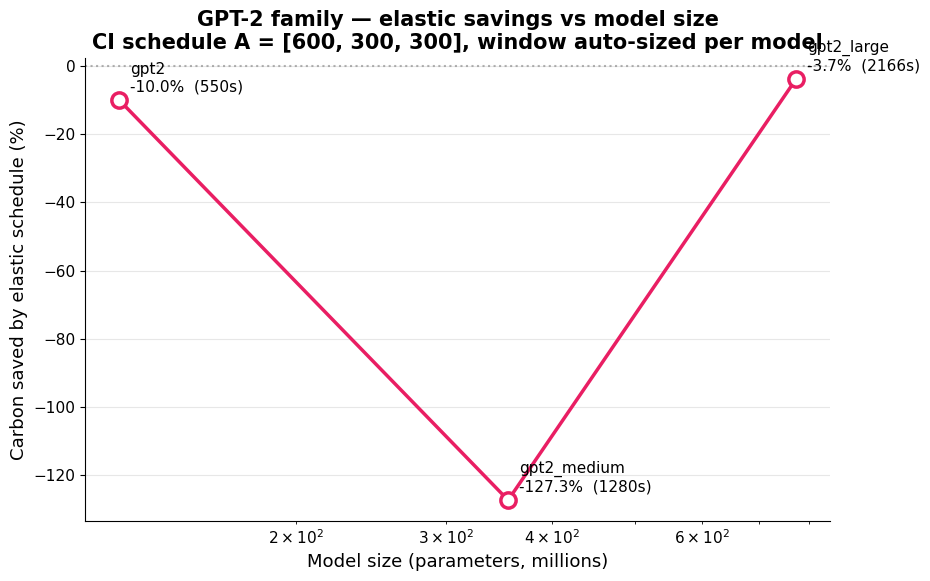


── Llama family  (A = [400, 100, 100]) ──
llama_1b        | window=   960s | best fixed=   26.0g | schedule=   25.1g | saved= +3.3%
llama_2b        | window=  1371s | best fixed=   42.7g | schedule=   40.9g | saved= +4.3%
llama_3b        | window=  1386s | best fixed=   50.8g | schedule=   46.5g | saved= +8.6%


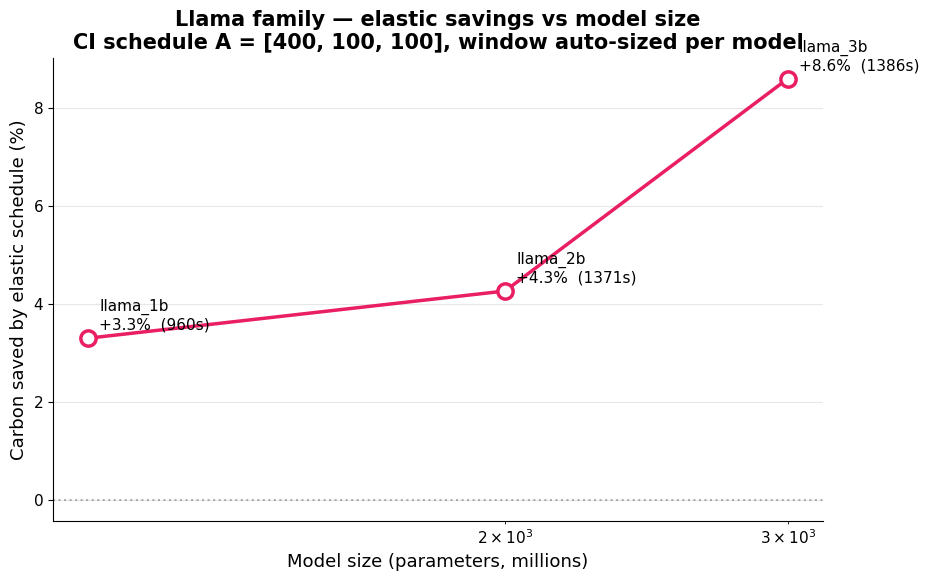

In [15]:
# run family
for family_key, fam in FAMILIES.items():
    print(f"\n── {fam['title']}  (A = {fam['A']}) ──")
    rows = _collect_family_rows(fam["models"], fam["A"])
    _plot_family(rows, fam["A"], fam["title"],
                 f"savings_vs_model_size_{family_key}.png")

## Cross-Model Analysis

Compare elastic scheduler savings across different model sizes and families (GPT-2, Llama).

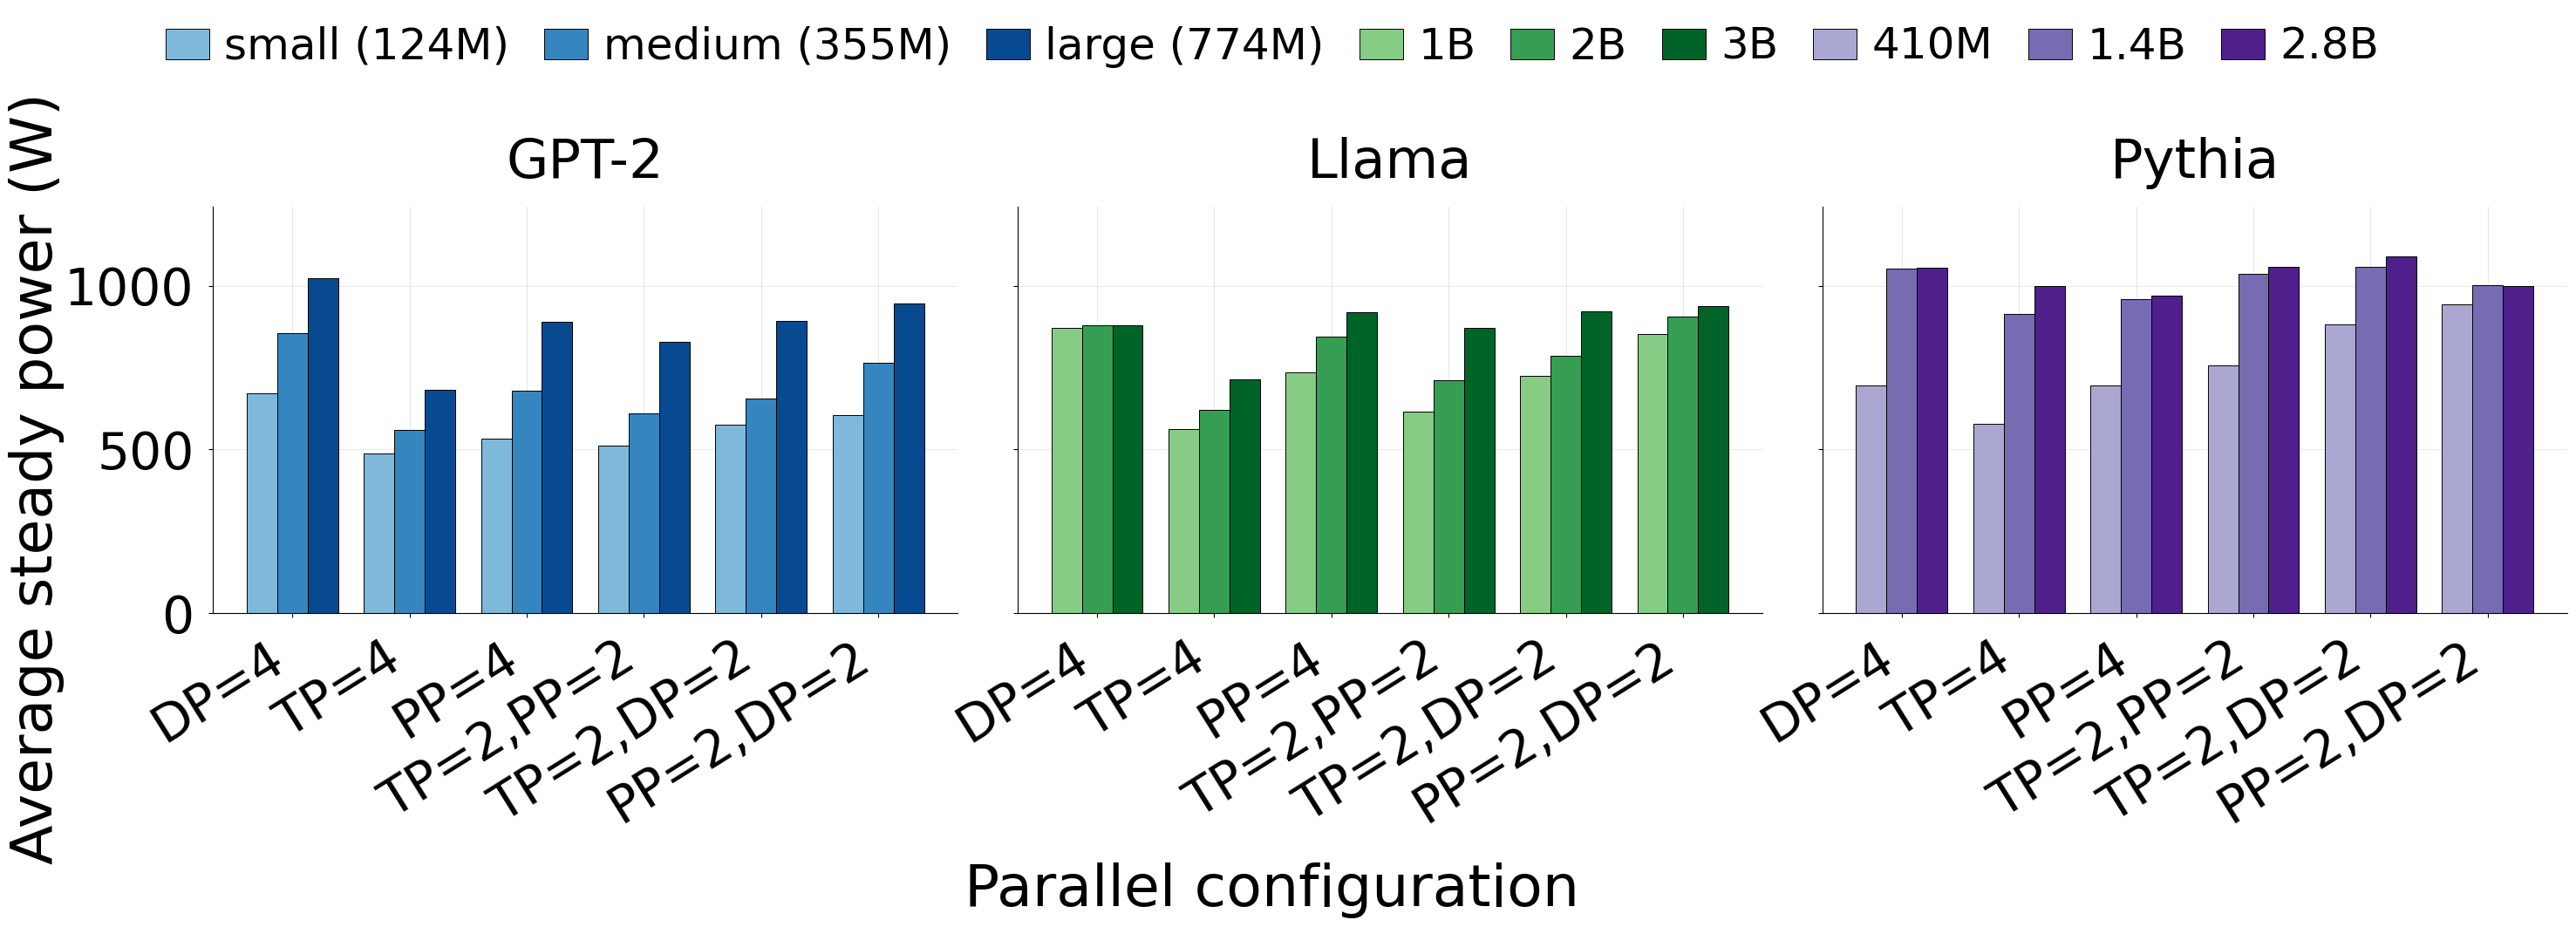


Saved: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/cross_model/power_landscape_by_family.png

Family   | Size               |       DP=4 |       TP=4 |       PP=4 |  TP=2,PP=2 |  TP=2,DP=2 |  PP=2,DP=2
-----------------------------------------------------------------------------------------------------------
GPT-2    | small (124M)       |      672.1 |      488.2 |      533.9 |      512.0 |      575.8 |      604.5
GPT-2    | medium (355M)      |      855.4 |      559.1 |      678.7 |      611.1 |      656.3 |      764.5
GPT-2    | large (774M)       |     1021.7 |      682.8 |      889.3 |      829.4 |      891.4 |      945.0
Llama    | 1B                 |      872.0 |      562.1 |      734.3 |      615.4 |      725.6 |      853.0
Llama    | 2B                 |      879.1 |      619.6 |      844.9 |      711.0 |      785.5 |      904.5
Llama    | 3B                 |      879.9 |      713.0 |      917.9 |      871.1 |      922.4 |      937.7
Pythia

In [31]:
# =====================================================================
# Power landscape plot
# =====================================================================
import os
import numpy as np
import matplotlib.pyplot as plt

BASE = globals().get("BASE", os.getcwd())

# =====================================================================
# Paper-ready plot hyperparameters
# Match throughput landscape plot apparent font size
# =====================================================================
PLOT_WIDTH = 30.0
PLOT_HEIGHT = 11.1

# Throughput reference figure is 20.0 x 7.4.
# This power plot is 1.5x larger, so scale fonts by 1.5x.
FONT_SCALE = PLOT_WIDTH / 20.0

TITLE_FONT_SIZE = int(round(30 * FONT_SCALE))      # 45
AXIS_FONT_SIZE = int(round(32 * FONT_SCALE))       # 48
TICK_FONT_SIZE = int(round(28 * FONT_SCALE))       # 42
X_TICK_FONT_SIZE = int(round(24 * FONT_SCALE))     # 36
LEGEND_FONT_SIZE = int(round(24 * FONT_SCALE))     # 36

X_LABEL_ROTATION = 32
TITLE_PAD = int(round(16 * FONT_SCALE))            # 24
TICK_PAD = int(round(8 * FONT_SCALE))              # 12
BAR_EDGE_WIDTH = 0.7
Y_LIMIT_MULTIPLIER = 1.14
FIG_DPI = 300

# Manual layout knobs. Do not use tight_layout() with large paper fonts.
LEFT_MARGIN = 0.095
RIGHT_MARGIN = 0.995
BOTTOM_MARGIN = 0.36

# Lower top margin to create clean space for one shared legend.
TOP_MARGIN = 0.78

WSPACE = 0.08

POWER_YLABEL = "Average steady power (W)"

CONFIG_ORDER = [
    ("elastic_tp1_pp1_dp4_power.csv", "DP=4"),
    ("elastic_tp4_pp1_dp1_power.csv", "TP=4"),
    ("elastic_tp1_pp4_dp1_power.csv", "PP=4"),
    ("elastic_tp2_pp2_dp1_power.csv", "TP=2,PP=2"),
    ("elastic_tp2_pp1_dp2_power.csv", "TP=2,DP=2"),
    ("elastic_tp1_pp2_dp2_power.csv", "PP=2,DP=2"),
]

POWER_LANDSCAPE_FAMILIES = {
    "GPT-2":  ["gpt2", "gpt2_medium", "gpt2_large"],
    "Llama":  ["llama_1b", "llama_2b", "llama_3b"],
    "Pythia": ["pythia_410m", "pythia_1_4b", "pythia_2_8b"],
}

SIZE_LABELS = {
    "gpt2": "small (124M)",
    "gpt2_medium": "medium (355M)",
    "gpt2_large": "large (774M)",
    "llama_1b": "1B",
    "llama_2b": "2B",
    "llama_3b": "3B",
    "pythia_410m": "410M",
    "pythia_1_4b": "1.4B",
    "pythia_2_8b": "2.8B",
}

FAMILY_CMAPS = {
    "GPT-2": plt.cm.Blues,
    "Llama": plt.cm.Greens,
    "Pythia": plt.cm.Purples,
}


# ---------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------
def _steady_avg_power(path, warmup_frac=0.2):
    """Steady-state mean total power (W). Returns None if file missing/too short."""
    if not os.path.exists(path):
        return None

    df = load_power_csv(path)

    if len(df) < 5:
        return None

    warmup = int(len(df) * warmup_frac)

    return df["total_power_W"].iloc[warmup:].mean()


def diagnose_power_logs():
    """Print a per-cell status report so missing bars can be traced to a cause."""
    print(f"{'family':8s} {'model':14s} {'config':14s} status")
    print("-" * 80)

    for fam_name, models in POWER_LANDSCAPE_FAMILIES.items():
        for m in models:
            ddir = os.path.join(BASE, "power_logs", m)

            if not os.path.isdir(ddir):
                print(f"{fam_name:8s} {m:14s} {'(all)':14s} DIR MISSING: {ddir}")
                continue

            for fn, lbl in CONFIG_ORDER:
                path = os.path.join(ddir, fn)

                if not os.path.exists(path):
                    status = "FILE MISSING"
                else:
                    try:
                        df = load_power_csv(path)

                        if len(df) < 5:
                            status = f"TOO SHORT ({len(df)} rows)"
                        else:
                            status = (
                                f"OK ({len(df)} rows, "
                                f"mean={df['total_power_W'].mean():.1f}W)"
                            )

                    except Exception as e:
                        status = f"LOAD ERROR: {type(e).__name__}: {e}"

                print(f"{fam_name:8s} {m:14s} {lbl:14s} {status}")

            expected = {fn for fn, _ in CONFIG_ORDER}
            extra = sorted(set(os.listdir(ddir)) - expected)

            if extra:
                print(f"{'':8s} {m:14s} {'(extras)':14s} {extra}")


# ---------------------------------------------------------------------
# Collect data per family/model
# ---------------------------------------------------------------------
landscape_data = {}

for fam_name, models in POWER_LANDSCAPE_FAMILIES.items():
    fam = {}

    for m in models:
        ddir = os.path.join(BASE, "power_logs", m)

        if not os.path.isdir(ddir):
            continue

        powers = [
            _steady_avg_power(os.path.join(ddir, fn))
            for fn, _ in CONFIG_ORDER
        ]

        if any(p is not None for p in powers):
            fam[m] = powers

    if fam:
        landscape_data[fam_name] = fam


# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
if not landscape_data:
    print("No power logs found for any family — nothing to plot.")
else:
    n_fam = len(landscape_data)

    fig, axes = plt.subplots(
        1,
        n_fam,
        figsize=(PLOT_WIDTH, PLOT_HEIGHT),
        sharey=True,
    )

    axes = np.atleast_1d(axes)

    global_max = max(
        p
        for fam in landscape_data.values()
        for ps in fam.values()
        for p in ps
        if p is not None
    )

    cfg_labels = [lbl for _, lbl in CONFIG_ORDER]
    x = np.arange(len(cfg_labels))

    # Collect all handles/labels for one shared figure-level legend.
    legend_handles = []
    legend_labels = []

    for idx, (ax, (fam_name, fam)) in enumerate(
        zip(axes, landscape_data.items())
    ):
        sizes = list(fam.keys())
        n_sizes = len(sizes)

        bar_w = 0.78 / max(n_sizes, 1)

        cmap = FAMILY_CMAPS.get(fam_name, plt.cm.Greys)
        shades = [
            cmap(0.45 + 0.45 * i / max(n_sizes - 1, 1))
            for i in range(n_sizes)
        ]

        for i, m in enumerate(sizes):
            powers = fam[m]
            offset = (i - (n_sizes - 1) / 2) * bar_w

            valid = [
                (xi + offset, p)
                for xi, p in zip(x, powers)
                if p is not None
            ]

            if not valid:
                continue

            xs, ps = zip(*valid)

            ax.bar(
                xs,
                ps,
                bar_w,
                color=shades[i],
                edgecolor="black",
                linewidth=BAR_EDGE_WIDTH,
                label=SIZE_LABELS.get(m, m),
            )

        ax.set_title(
            fam_name,
            fontsize=TITLE_FONT_SIZE,
            fontweight="normal",
            pad=TITLE_PAD,
        )

        ax.set_xticks(x)
        ax.set_xticklabels(
            cfg_labels,
            fontsize=X_TICK_FONT_SIZE,
            rotation=X_LABEL_ROTATION,
            ha="right",
        )

        ax.tick_params(
            axis="both",
            labelsize=TICK_FONT_SIZE,
            pad=TICK_PAD,
        )

        ax.set_ylim(0, global_max * Y_LIMIT_MULTIPLIER)
        ax.grid(True, axis="y", alpha=0.25)
        ax.set_axisbelow(True)

        # Do not draw per-axis legends.
        # Just collect the handles/labels for a single global legend.
        handles, labels = ax.get_legend_handles_labels()
        legend_handles.extend(handles)
        legend_labels.extend(labels)

    # Remove duplicate legend entries while preserving order.
    seen = set()
    unique_handles = []
    unique_labels = []

    for h, l in zip(legend_handles, legend_labels):
        if l not in seen:
            unique_handles.append(h)
            unique_labels.append(l)
            seen.add(l)

    fig.legend(
        unique_handles,
        unique_labels,
        fontsize=LEGEND_FONT_SIZE,
        frameon=False,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.985),
        ncol=9,
        handlelength=1.0,
        handletextpad=0.35,
        columnspacing=0.8,
        borderaxespad=0.0,
    )

    fig.supylabel(
        POWER_YLABEL,
        fontsize=AXIS_FONT_SIZE,
        x=0.017,
    )

    fig.supxlabel(
        "Parallel configuration",
        fontsize=AXIS_FONT_SIZE,
        y=0.045,
    )

    fig.subplots_adjust(
        left=LEFT_MARGIN,
        right=RIGHT_MARGIN,
        bottom=BOTTOM_MARGIN,
        top=TOP_MARGIN,
        wspace=WSPACE,
    )

    out_dir = os.path.join(BASE, "figures", "experiment_plots", "cross_model")
    os.makedirs(out_dir, exist_ok=True)

    out_path = os.path.join(out_dir, "power_landscape_by_family.png")

    fig.savefig(
        out_path,
        dpi=FIG_DPI,
        bbox_inches="tight",
        pad_inches=0.04,
    )

    plt.show()

    print(f"\nSaved: {out_path}")

    # ---------------------------------------------------------------------
    # Compact summary table
    # ---------------------------------------------------------------------
    header = (
        f"{'Family':8s} | {'Size':18s} | "
        + " | ".join(f"{lbl:>10s}" for lbl in cfg_labels)
    )

    print("\n" + header)
    print("-" * len(header))

    for fam_name, fam in landscape_data.items():
        for m, powers in fam.items():
            cells = " | ".join(
                f"{p:10.1f}" if p is not None else f"{'-':>10s}"
                for p in powers
            )

            print(f"{fam_name:8s} | {SIZE_LABELS.get(m, m):18s} | {cells}")

[info] gpt2_medium: summary token count mismatch (12288039 vs expected 3276800); summary runtime recompute for DP=4, TP=2,DP=2; power-log runtime fallback for TP=4, PP=4, TP=2,PP=2, PP=2,DP=2 (/u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/gpt2_medium/summary_table.csv)


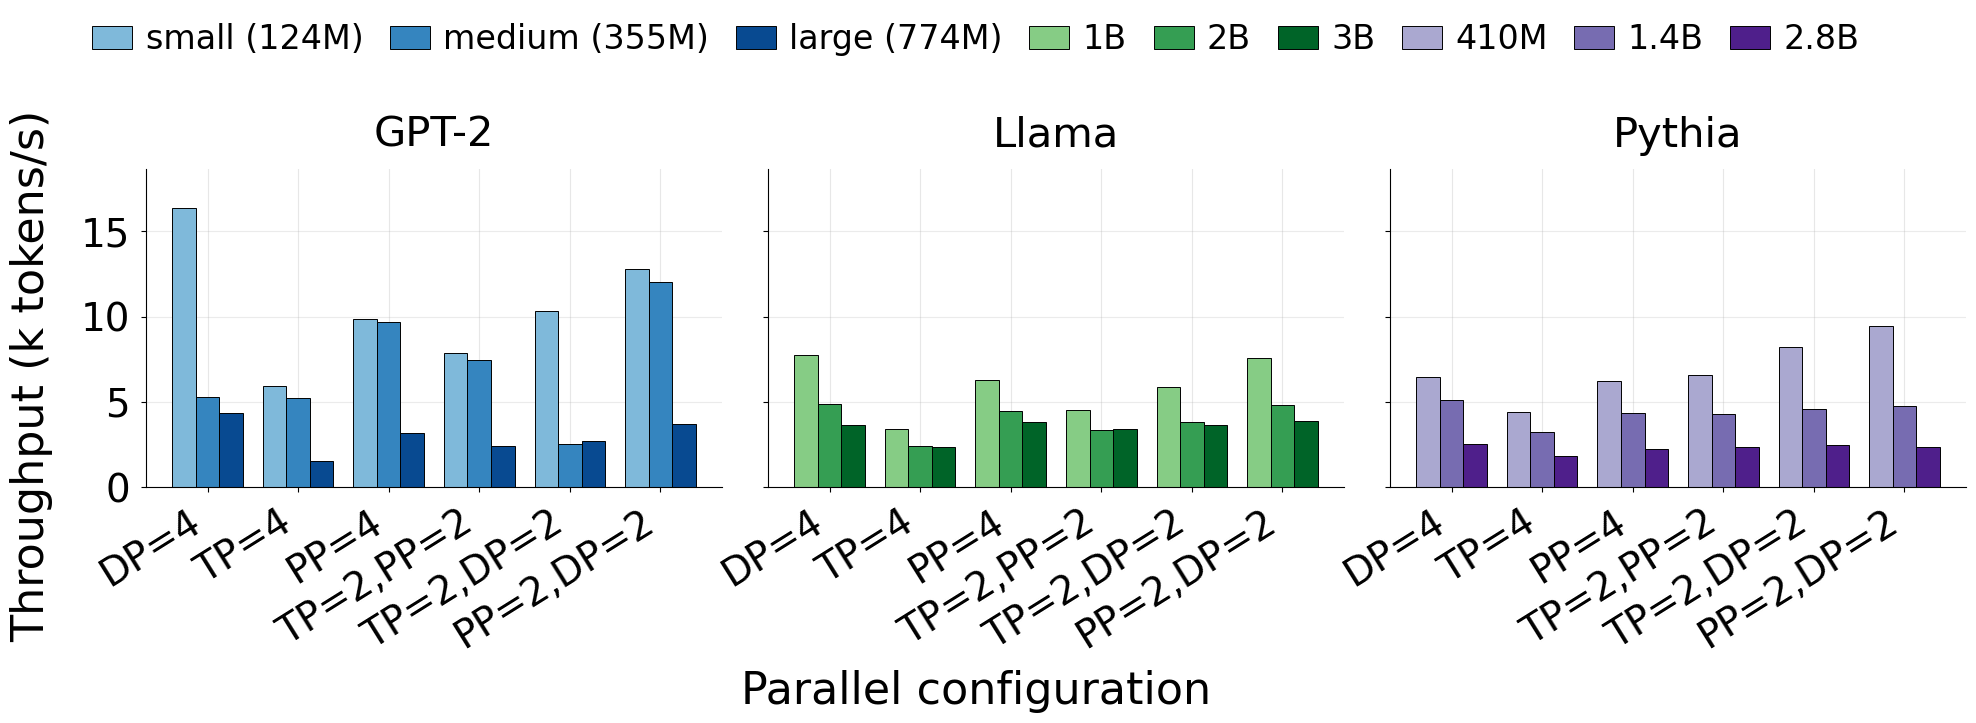


Saved: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/cross_model/throughput_landscape_by_family.png

Family   | Size               |       DP=4 |       TP=4 |       PP=4 |  TP=2,PP=2 |  TP=2,DP=2 |  PP=2,DP=2
-----------------------------------------------------------------------------------------------------------
GPT-2    | small (124M)       |       16.3 |        6.0 |        9.8 |        7.8 |       10.3 |       12.8
GPT-2    | medium (355M)      |        5.3 |        5.2 |        9.7 |        7.4 |        2.6 |       12.0
GPT-2    | large (774M)       |        4.4 |        1.5 |        3.2 |        2.4 |        2.7 |        3.7
Llama    | 1B                 |        7.7 |        3.4 |        6.3 |        4.5 |        5.9 |        7.6
Llama    | 2B                 |        4.9 |        2.4 |        4.5 |        3.3 |        3.8 |        4.8
Llama    | 3B                 |        3.7 |        2.4 |        3.8 |        3.4 |        3.7 |        3.9
P

In [37]:
# =====================================================================
# Throughput landscape plot
# =====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = globals().get("BASE", os.getcwd())

# =====================================================================
# Paper-ready plot hyperparameters
# =====================================================================
PLOT_WIDTH = 20.0
PLOT_HEIGHT = 7.4

TITLE_FONT_SIZE = 30
AXIS_FONT_SIZE = 32
TICK_FONT_SIZE = 28
X_TICK_FONT_SIZE = 24
LEGEND_FONT_SIZE = 24

X_LABEL_ROTATION = 32
TITLE_PAD = 16
TICK_PAD = 8
BAR_EDGE_WIDTH = 0.7
Y_LIMIT_MULTIPLIER = 1.14
FIG_DPI = 300

# Manual layout knobs. Do not use tight_layout() with large paper fonts.
LEFT_MARGIN = 0.085
RIGHT_MARGIN = 0.995
BOTTOM_MARGIN = 0.35
TOP_MARGIN = 0.78
WSPACE = 0.08

# Plot throughput in k tokens/s instead of raw tokens/s.
THROUGHPUT_SCALE = 1000.0
THROUGHPUT_YLABEL = "Throughput (k tokens/s)"

THROUGHPUT_CONFIG_ORDER = [
    "DP=4",
    "TP=4",
    "PP=4",
    "TP=2,PP=2",
    "TP=2,DP=2",
    "PP=2,DP=2",
]

THROUGHPUT_CONFIG_FILES = globals().get("CONFIG_ORDER", [
    ("elastic_tp1_pp1_dp4_power.csv", "DP=4"),
    ("elastic_tp4_pp1_dp1_power.csv", "TP=4"),
    ("elastic_tp1_pp4_dp1_power.csv", "PP=4"),
    ("elastic_tp2_pp2_dp1_power.csv", "TP=2,PP=2"),
    ("elastic_tp2_pp1_dp2_power.csv", "TP=2,DP=2"),
    ("elastic_tp1_pp2_dp2_power.csv", "PP=2,DP=2"),
])

THROUGHPUT_CONFIG_TO_FILE = {
    label: filename for filename, label in THROUGHPUT_CONFIG_FILES
}

THROUGHPUT_FAMILIES = globals().get("POWER_LANDSCAPE_FAMILIES", {
    "GPT-2":  ["gpt2", "gpt2_medium", "gpt2_large"],
    "Llama":  ["llama_1b", "llama_2b", "llama_3b"],
    "Pythia": ["pythia_410m", "pythia_1_4b", "pythia_2_8b"],
})

THROUGHPUT_SIZE_LABELS = globals().get("SIZE_LABELS", {
    "gpt2": "small (124M)",
    "gpt2_medium": "medium (355M)",
    "gpt2_large": "large (774M)",
    "llama_1b": "1B",
    "llama_2b": "2B",
    "llama_3b": "3B",
    "pythia_410m": "410M",
    "pythia_1_4b": "1.4B",
    "pythia_2_8b": "2.8B",
})

THROUGHPUT_FAMILY_CMAPS = globals().get("FAMILY_CMAPS", {
    "GPT-2": plt.cm.Blues,
    "Llama": plt.cm.Greens,
    "Pythia": plt.cm.Purples,
})


def _norm_config_label(label):
    return str(label).replace("\n", "").replace(" ", "").strip().lower()


def _summary_table_path(model_name):
    candidates = [
        os.path.join(BASE, "figures", "experiment_plots", model_name, "summary_table.csv"),
        os.path.join(BASE, "plots", model_name, "summary_table.csv"),
    ]

    for path in candidates:
        if os.path.exists(path):
            return path

    return candidates[0]


def _find_throughput_col(df):
    for col in df.columns:
        key = str(col).strip().lower().replace(" ", "")

        if key in {
            "tput(tok/s)",
            "throughput(tok/s)",
            "throughput_tok_s",
            "tok/s",
            "tokens/s",
        }:
            return col

    return None


def _find_time_col(df):
    for col in df.columns:
        key = str(col).strip().lower().replace(" ", "")

        if key in {
            "time(s)",
            "exptime(s)",
            "traintime(s)",
            "duration(s)",
            "duration_s",
        }:
            return col

    return None


def _infer_total_tokens(static_df, tput_col):
    time_col = _find_time_col(static_df)

    if time_col is None:
        return None

    totals = []

    for _, row in static_df.iterrows():
        if pd.isna(row.get(tput_col)) or pd.isna(row.get(time_col)):
            continue

        throughput = float(row[tput_col])
        duration_s = float(row[time_col])

        if throughput > 0 and duration_s > 0:
            totals.append(throughput * duration_s)

    if not totals:
        return None

    return float(np.median(totals))


def _default_total_tokens():
    if "total_tokens" in globals():
        return float(globals()["total_tokens"])

    if all(k in globals() for k in ("TRAIN_ITERS", "GLOBAL_BATCH", "SEQ_LEN")):
        return float(TRAIN_ITERS * GLOBAL_BATCH * SEQ_LEN)

    return 200.0 * 16.0 * 1024.0


def _power_log_duration_s(model_name, config_label):
    filename = THROUGHPUT_CONFIG_TO_FILE.get(config_label)

    if filename is None:
        return None

    path = os.path.join(BASE, "power_logs", model_name, filename)

    if not os.path.exists(path):
        return None

    try:
        if "load_power_csv" in globals():
            df = load_power_csv(path)
        else:
            df = pd.read_csv(path)
    except Exception:
        return None

    if len(df) < 5:
        return None

    interval_s = float(globals().get("INTERVAL_SECONDS", 0.5))

    return len(df) * interval_s


def _load_summary_throughput(model_name):
    path = _summary_table_path(model_name)
    values = [None] * len(THROUGHPUT_CONFIG_ORDER)
    status_parts = []
    expected_total_tokens = _default_total_tokens()

    if os.path.exists(path):
        df = pd.read_csv(path)
        tput_col = _find_throughput_col(df)

        if tput_col is None or "Config" not in df.columns:
            status_parts.append("throughput column missing")
        else:
            if "Type" in df.columns:
                static_df = df[df["Type"].astype(str).str.lower().eq("static")]
            else:
                static_df = df

            summary_total_tokens = _infer_total_tokens(static_df, tput_col)
            time_col = _find_time_col(static_df)

            by_config = {
                _norm_config_label(row["Config"]): row
                for _, row in static_df.iterrows()
            }

            summary_matches_notebook = (
                summary_total_tokens is not None
                and expected_total_tokens > 0
                and abs(summary_total_tokens - expected_total_tokens)
                / expected_total_tokens <= 0.10
            )

            if summary_total_tokens is not None and not summary_matches_notebook:
                status_parts.append(
                    f"summary token count mismatch "
                    f"({summary_total_tokens:.0f} vs expected {expected_total_tokens:.0f})"
                )

            recomputed_from_summary_time = []

            for i, label in enumerate(THROUGHPUT_CONFIG_ORDER):
                row = by_config.get(_norm_config_label(label))

                if row is None:
                    continue

                if summary_matches_notebook and not pd.isna(row[tput_col]):
                    values[i] = float(row[tput_col])
                    continue

                if time_col is not None and not pd.isna(row[time_col]):
                    duration_s = float(row[time_col])

                    if duration_s > 0:
                        values[i] = expected_total_tokens / duration_s
                        recomputed_from_summary_time.append(label)

            if recomputed_from_summary_time:
                status_parts.append(
                    "summary runtime recompute for "
                    + ", ".join(recomputed_from_summary_time)
                )
            else:
                status_parts.append("summary")
    else:
        status_parts.append("summary missing")

    filled_from_logs = []

    for i, label in enumerate(THROUGHPUT_CONFIG_ORDER):
        if values[i] is not None:
            continue

        duration_s = _power_log_duration_s(model_name, label)

        if duration_s is None or duration_s <= 0:
            continue

        values[i] = expected_total_tokens / duration_s
        filled_from_logs.append(label)

    if filled_from_logs:
        status_parts.append(
            "power-log runtime fallback for " + ", ".join(filled_from_logs)
        )

    if not any(v is not None for v in values):
        status_parts.append("no static throughput rows")

    return values, path, "; ".join(status_parts)


# ---------------------------------------------------------------------
# Collect data per family/model from generated summary tables.
# ---------------------------------------------------------------------
throughput_data = {}
throughput_sources = {}

for fam_name, models in THROUGHPUT_FAMILIES.items():
    fam = {}

    for model_name in models:
        values, path, status = _load_summary_throughput(model_name)
        throughput_sources[model_name] = (path, status)

        if any(v is not None for v in values):
            fam[model_name] = values

            if "power-log runtime fallback" in status:
                print(f"[info] {model_name}: {status} ({path})")
        else:
            print(f"[skip] {model_name}: {status} ({path})")

    if fam:
        throughput_data[fam_name] = fam


# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
if not throughput_data:
    print("No throughput summaries found for any family - nothing to plot.")
else:
    n_fam = len(throughput_data)

    fig, axes = plt.subplots(
        1,
        n_fam,
        figsize=(PLOT_WIDTH, PLOT_HEIGHT),
        sharey=True,
    )

    axes = np.atleast_1d(axes)

    global_max = max(
        t / THROUGHPUT_SCALE
        for fam in throughput_data.values()
        for ts in fam.values()
        for t in ts
        if t is not None
    )

    x = np.arange(len(THROUGHPUT_CONFIG_ORDER))

    # Collect legend entries from all panels, then draw one shared legend.
    legend_handles = []
    legend_labels = []

    for idx, (ax, (fam_name, fam)) in enumerate(
        zip(axes, throughput_data.items())
    ):
        sizes = list(fam.keys())
        n_sizes = len(sizes)

        bar_w = 0.78 / max(n_sizes, 1)

        cmap = THROUGHPUT_FAMILY_CMAPS.get(fam_name, plt.cm.Greys)
        shades = [
            cmap(0.45 + 0.45 * i / max(n_sizes - 1, 1))
            for i in range(n_sizes)
        ]

        for i, model_name in enumerate(sizes):
            tputs = fam[model_name]
            offset = (i - (n_sizes - 1) / 2) * bar_w

            valid = [
                (xi + offset, t / THROUGHPUT_SCALE)
                for xi, t in zip(x, tputs)
                if t is not None
            ]

            if not valid:
                continue

            xs, ts = zip(*valid)

            ax.bar(
                xs,
                ts,
                bar_w,
                color=shades[i],
                edgecolor="black",
                linewidth=BAR_EDGE_WIDTH,
                label=THROUGHPUT_SIZE_LABELS.get(model_name, model_name),
            )

        ax.set_title(
            fam_name,
            fontsize=TITLE_FONT_SIZE,
            fontweight="normal",
            pad=TITLE_PAD,
        )

        ax.set_xticks(x)
        ax.set_xticklabels(
            THROUGHPUT_CONFIG_ORDER,
            fontsize=X_TICK_FONT_SIZE,
            rotation=X_LABEL_ROTATION,
            ha="right",
        )

        ax.tick_params(
            axis="both",
            labelsize=TICK_FONT_SIZE,
            pad=TICK_PAD,
        )

        ax.set_ylim(0, global_max * Y_LIMIT_MULTIPLIER)
        ax.grid(True, axis="y", alpha=0.25)
        ax.set_axisbelow(True)

        handles, labels = ax.get_legend_handles_labels()
        legend_handles.extend(handles)
        legend_labels.extend(labels)

    # One shared legend across the top of the whole figure.
    seen = set()
    unique_handles = []
    unique_labels = []

    for h, l in zip(legend_handles, legend_labels):
        if l not in seen:
            unique_handles.append(h)
            unique_labels.append(l)
            seen.add(l)

    fig.legend(
        unique_handles,
        unique_labels,
        fontsize=LEGEND_FONT_SIZE,
        frameon=False,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=9,
        handlelength=1.2,
        handletextpad=0.4,
        columnspacing=0.8,
        borderaxespad=0.0,
    )

    fig.supylabel(
        THROUGHPUT_YLABEL,
        fontsize=AXIS_FONT_SIZE,
        x=0.017,
    )

    fig.supxlabel(
        "Parallel configuration",
        fontsize=AXIS_FONT_SIZE,
        y=0.045,
    )

    fig.subplots_adjust(
        left=LEFT_MARGIN,
        right=RIGHT_MARGIN,
        bottom=BOTTOM_MARGIN,
        top=TOP_MARGIN,
        wspace=WSPACE,
    )

    out_dir = os.path.join(BASE, "figures", "experiment_plots", "cross_model")
    os.makedirs(out_dir, exist_ok=True)

    out_path = os.path.join(out_dir, "throughput_landscape_by_family.png")

    fig.savefig(
        out_path,
        dpi=FIG_DPI,
        bbox_inches="tight",
        pad_inches=0.04,
    )

    plt.show()

    print(f"\nSaved: {out_path}")

    rows = []

    header = (
        f"{'Family':8s} | {'Size':18s} | "
        + " | ".join(f"{lbl:>10s}" for lbl in THROUGHPUT_CONFIG_ORDER)
    )

    print("\n" + header)
    print("-" * len(header))

    for fam_name, fam in throughput_data.items():
        for model_name, tputs in fam.items():
            cells = " | ".join(
                f"{(t / THROUGHPUT_SCALE):10.1f}" if t is not None else f"{'-':>10s}"
                for t in tputs
            )

            size_label = THROUGHPUT_SIZE_LABELS.get(model_name, model_name)

            print(f"{fam_name:8s} | {size_label:18s} | {cells}")

            row = {
                "Family": fam_name,
                "Model": model_name,
                "Size": size_label,
            }

            row.update({
                f"{label}_tok_s": t
                for label, t in zip(THROUGHPUT_CONFIG_ORDER, tputs)
            })

            row.update({
                f"{label}_k_tok_s": (
                    t / THROUGHPUT_SCALE if t is not None else None
                )
                for label, t in zip(THROUGHPUT_CONFIG_ORDER, tputs)
            })

            rows.append(row)

    csv_path = os.path.join(out_dir, "throughput_landscape_by_family.csv")
    pd.DataFrame(rows).to_csv(csv_path, index=False)

    print(f"Saved: {csv_path}")